In [4]:
%pip install pandas
%pip install numpy
%pip install scikit-learn
%pip install statsmodels
%pip install matplotlib


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV
)

from sklearn.compose import ColumnTransformer

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.pipeline import Pipeline

from sklearn.neighbors import KNeighborsRegressor

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    pairwise_distances
)

from scipy.spatial.distance import cdist

## Week 8

Included here: K-Nearest Neighbors (KNN)

In [6]:
df_ecom = pd.read_csv(
    "US  E-commerce records 2020.csv",
    encoding="latin1"
)

df_retail = pd.read_csv(
    "retail_store_inventory.csv"
)

print("E-Commerce shape:", df_ecom.shape)
print("Retail shape:", df_retail.shape)

FileNotFoundError: [Errno 2] No such file or directory: 'US  E-commerce records 2020.csv'

In [ ]:
# same features as previously 

numeric_ecom = [
    "Sales",
    "Quantity",
    "Discount"
]

categorical_ecom = [
    "Category",
    "Sub-Category",
    "Region",
    "Segment"
]

features_ecom = (
    numeric_ecom
    + categorical_ecom
)


numeric_retail = [
    "Demand Forecast",
    "Inventory Level",
    "Units Ordered",
    "Price",
    "Discount",
    "Competitor Pricing",
    "Holiday/Promotion"
]

categorical_retail = [
    "Category",
    "Region",
    "Weather Condition",
    "Seasonality"
]

features_retail = (
    numeric_retail
    + categorical_retail
)

Scaling:

In [ ]:
def create_knn_preprocessor(
    numeric_features,
    categorical_features
):

    return ColumnTransformer(
        transformers=[
            (
                "numeric",
                StandardScaler(),
                numeric_features
            ),
            (
                "categorical",
                OneHotEncoder(
                    drop="first",
                    handle_unknown="ignore",
                    sparse_output=False
                ),
                categorical_features
            )
        ],
        sparse_threshold=0
    )

### Dataset 1: E-Commerce

In [ ]:
# 80% - training, 20% - test

ecom_data = df_ecom[
    features_ecom + ["Profit"]
].dropna().copy()

X_ecom = ecom_data[
    features_ecom
]

y_ecom = ecom_data[
    "Profit"
]

(
    X_train_ecom,
    X_test_ecom,
    y_train_ecom,
    y_test_ecom
) = train_test_split(
    X_ecom,
    y_ecom,
    test_size=0.20,
    random_state=42
)

print(
    "Training observations:",
    len(X_train_ecom)
)

print(
    "Test observations:",
    len(X_test_ecom)
)

Training observations: 2649
Test observations: 663


In [ ]:
distance_sample_ecom = (
    X_train_ecom
    .sample(
        n=100,
        random_state=42
    )
)

distance_preprocessor_ecom = (
    create_knn_preprocessor(
        numeric_ecom,
        categorical_ecom
    )
)

X_distance_ecom = (
    distance_preprocessor_ecom
    .fit_transform(
        distance_sample_ecom
    )
)

print(
    X_distance_ecom.shape
)

(100, 25)


I compared four definitions of distance: Euclidean, Manhattan, Minkowski (p=3 - to not repeat Euclidean and Manhattan with 1 and 2), and cosine.

In [ ]:
ecom_euclidean = pairwise_distances(
    X_distance_ecom,
    metric="euclidean"
)

ecom_manhattan = pairwise_distances(
    X_distance_ecom,
    metric="manhattan"
)

ecom_minkowski = pairwise_distances(
    X_distance_ecom,
    metric="minkowski",
    p=3
)

ecom_cosine = pairwise_distances(
    X_distance_ecom,
    metric="cosine"
)

In [ ]:
def summarize_distance_matrix(
    matrix,
    metric_name
):

    values = matrix[
        np.triu_indices_from(
            matrix,
            k=1
        )
    ]

    return {
        "Metric": metric_name,
        "Mean Distance": values.mean(),
        "Median Distance": np.median(values),
        "Minimum Distance": values.min(),
        "Maximum Distance": values.max()
    }

In [ ]:
ecom_distance_summary = pd.DataFrame([
    summarize_distance_matrix(
        ecom_euclidean,
        "Euclidean"
    ),

    summarize_distance_matrix(
        ecom_manhattan,
        "Manhattan"
    ),

    summarize_distance_matrix(
        ecom_minkowski,
        "Minkowski (p=3)"
    ),

    summarize_distance_matrix(
        ecom_cosine,
        "Cosine"
    )
])

display(
    ecom_distance_summary.round(4)
)

,Metric,Mean Distance,Median Distance,Minimum Distance,Maximum Distance
0,Euclidean,3.0176,2.7747,0.0423,9.5863
1,Manhattan,7.0997,6.9770,0.0423,19.7870
2,Minkowski (p=3),2.3973,2.0349,0.0423,8.7809
3,Cosine,0.8373,0.8458,0.0002,1.6000


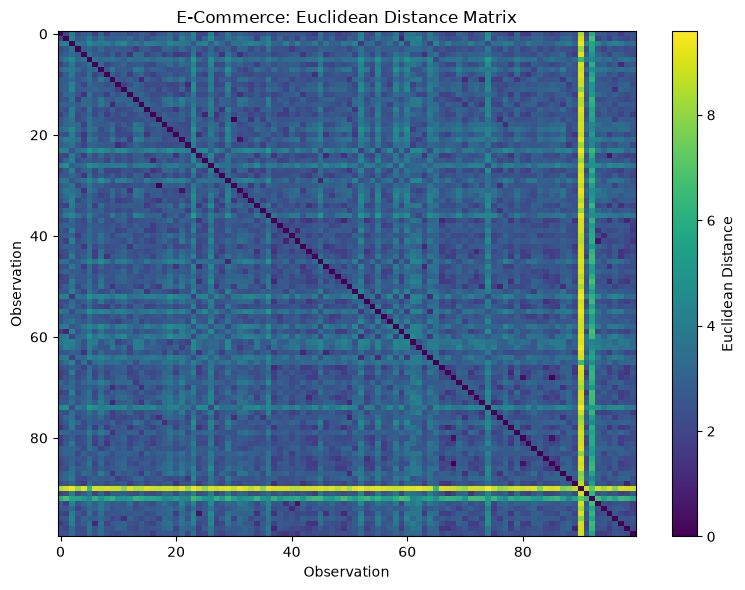

In [ ]:
plt.figure(
    figsize=(8, 6)
)

plt.imshow(
    ecom_euclidean,
    aspect="auto"
)

plt.colorbar(
    label="Euclidean Distance"
)

plt.title(
    "E-Commerce: Euclidean Distance Matrix"
)

plt.xlabel(
    "Observation"
)

plt.ylabel(
    "Observation"
)

plt.tight_layout()

plt.show()

This shows the pair distances between observations. The diagonal contains zeros - because each observation has a distance of zero from itself. Areas with small distances correspond to observations that are more similar to each other

### Now let's compare several KNN metrics for E-Commerce:

In [ ]:
def evaluate_knn_metrics(
    X_train,
    X_test,
    y_train,
    y_test,
    numeric_features,
    categorical_features
):

    results = []

    metrics = [
        (
            "Euclidean",
            "euclidean",
            None
        ),
        (
            "Manhattan",
            "manhattan",
            None
        ),
        (
            "Minkowski (p=3)",
            "minkowski",
            3
        ),
        (
            "Cosine",
            "cosine",
            None
        )
    ]

    for (
        name,
        metric,
        p_value
    ) in metrics:

        knn_settings = {
            "n_neighbors": 5,
            "weights": "distance",
            "metric": metric,
            "algorithm": "brute"
        }

        if metric == "minkowski":
            knn_settings["p"] = p_value

        model = Pipeline(
            steps=[
                (
                    "preprocessor",
                    create_knn_preprocessor(
                        numeric_features,
                        categorical_features
                    )
                ),
                (
                    "knn",
                    KNeighborsRegressor(
                        **knn_settings
                    )
                )
            ]
        )

        model.fit(
            X_train,
            y_train
        )

        predictions = model.predict(
            X_test
        )

        results.append({
            "Distance": name,

            "R2": r2_score(
                y_test,
                predictions
            ),

            "MAE": mean_absolute_error(
                y_test,
                predictions
            ),

            "RMSE": np.sqrt(
                mean_squared_error(
                    y_test,
                    predictions
                )
            )
        })

    return pd.DataFrame(
        results
    )

In [ ]:
ecom_distance_results = (
    evaluate_knn_metrics(
        X_train_ecom,
        X_test_ecom,
        y_train_ecom,
        y_test_ecom,
        numeric_ecom,
        categorical_ecom
    )
)

display(
    ecom_distance_results.round(4)
)

,Distance,R2,MAE,RMSE
0,Euclidean,0.5226,45.1484,243.9163
1,Manhattan,0.3675,48.5529,280.7510
2,Minkowski (p=3),0.5760,43.6829,229.8766
3,Cosine,0.2737,48.7363,300.8676


The number of neighbors was 5. 
Among everything tested, Minkowski produced the highest R² for the E-Commerce dataset and the lowest error.

### Dataset 2: Retail Store Inventory

In [ ]:
retail_data = df_retail[
    features_retail
    + ["Units Sold"]
].dropna().copy()

df_retail_sample = (
    retail_data
    .sample(
        n=10000,
        random_state=42
    )
)

X_retail = df_retail_sample[
    features_retail
]

y_retail = df_retail_sample[
    "Units Sold"
]

(
    X_train_retail,
    X_test_retail,
    y_train_retail,
    y_test_retail
) = train_test_split(
    X_retail,
    y_retail,
    test_size=0.20,
    random_state=42
)

print(
    "Training observations:",
    len(X_train_retail)
)

print(
    "Test observations:",
    len(X_test_retail)
)

Training observations: 8000
Test observations: 2000


In [ ]:
distance_sample_retail = (
    X_train_retail
    .sample(
        n=100,
        random_state=42
    )
)

distance_preprocessor_retail = (
    create_knn_preprocessor(
        numeric_retail,
        categorical_retail
    )
)

X_distance_retail = (
    distance_preprocessor_retail
    .fit_transform(
        distance_sample_retail
    )
)

In [ ]:
retail_euclidean = pairwise_distances(
    X_distance_retail,
    metric="euclidean"
)

retail_manhattan = pairwise_distances(
    X_distance_retail,
    metric="manhattan"
)

retail_minkowski = pairwise_distances(
    X_distance_retail,
    metric="minkowski",
    p=3
)

retail_cosine = pairwise_distances(
    X_distance_retail,
    metric="cosine"
)

In [ ]:
retail_distance_summary = pd.DataFrame([
    summarize_distance_matrix(
        retail_euclidean,
        "Euclidean"
    ),

    summarize_distance_matrix(
        retail_manhattan,
        "Manhattan"
    ),

    summarize_distance_matrix(
        retail_minkowski,
        "Minkowski (p=3)"
    ),

    summarize_distance_matrix(
        retail_cosine,
        "Cosine"
    )
])

display(
    retail_distance_summary.round(4)
)

,Metric,Mean Distance,Median Distance,Minimum Distance,Maximum Distance
0,Euclidean,4.2304,4.2118,1.5592,7.4152
1,Manhattan,12.4137,12.3448,3.1183,22.6066
2,Minkowski (p=3),3.1129,3.0843,1.3385,5.4440
3,Cosine,0.9383,0.9406,0.1080,1.7841


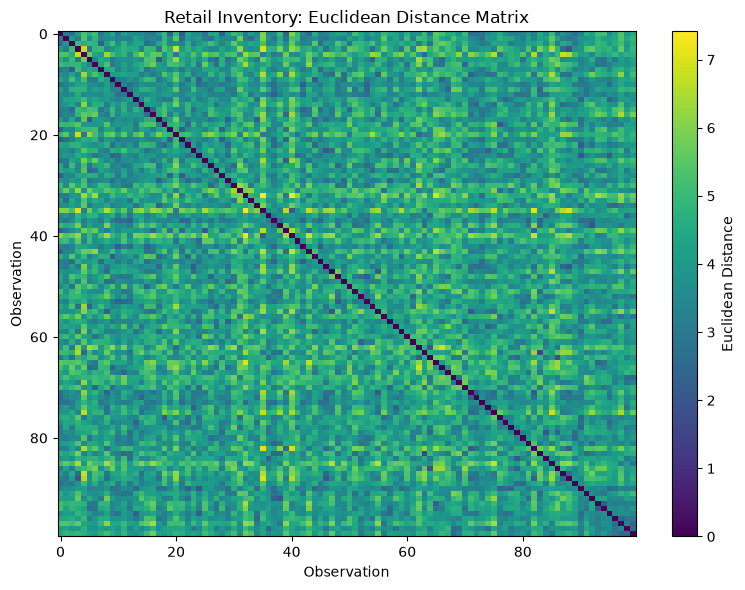

In [ ]:
plt.figure(
    figsize=(8, 6)
)

plt.imshow(
    retail_euclidean,
    aspect="auto"
)

plt.colorbar(
    label="Euclidean Distance"
)

plt.title(
    "Retail Inventory: Euclidean Distance Matrix"
)

plt.xlabel(
    "Observation"
)

plt.ylabel(
    "Observation"
)

plt.tight_layout()

plt.show()

In [ ]:
retail_distance_results = (
    evaluate_knn_metrics(
        X_train_retail,
        X_test_retail,
        y_train_retail,
        y_test_retail,
        numeric_retail,
        categorical_retail
    )
)

display(
    retail_distance_results.round(4)
)

,Distance,R2,MAE,RMSE
0,Euclidean,0.9152,25.7379,32.0108
1,Manhattan,0.8794,29.5316,38.1729
2,Minkowski (p=3),0.9200,25.2435,31.1024
3,Cosine,0.9099,26.5700,32.9997


For the Retail dataset, agian Minkowski with p=3 produced the highest R² and the lowest error

## Now let's compare everything for this week for both datasets

In [ ]:
week8_distance_comparison = pd.concat(
    [
        ecom_distance_summary.assign(
            Dataset="E-Commerce"
        ),
        retail_distance_summary.assign(
            Dataset="Retail Inventory"
        )
    ],
    ignore_index=True
)

display(
    week8_distance_comparison[
        [
            "Dataset",
            "Metric",
            "Mean Distance",
            "Median Distance",
            "Minimum Distance",
            "Maximum Distance"
        ]
    ].round(4)
)

,Dataset,Metric,Mean Distance,Median Distance,Minimum Distance,Maximum Distance
0,E-Commerce,Euclidean,3.0176,2.7747,0.0423,9.5863
1,E-Commerce,Manhattan,7.0997,6.9770,0.0423,19.7870
2,E-Commerce,Minkowski (p=3),2.3973,2.0349,0.0423,8.7809
3,E-Commerce,Cosine,0.8373,0.8458,0.0002,1.6000
4,Retail Inventory,Euclidean,4.2304,4.2118,1.5592,7.4152
5,Retail Inventory,Manhattan,12.4137,12.3448,3.1183,22.6066
6,Retail Inventory,Minkowski (p=3),3.1129,3.0843,1.3385,5.4440
7,Retail Inventory,Cosine,0.9383,0.9406,0.1080,1.7841


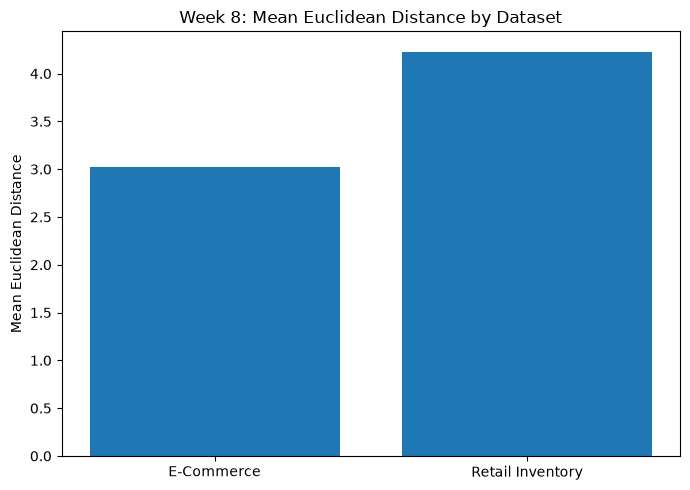

In [ ]:
euclidean_comparison = pd.DataFrame({
    "Dataset": [
        "E-Commerce",
        "Retail Inventory"
    ],
    "Mean Euclidean Distance": [
        ecom_distance_summary.loc[
            ecom_distance_summary["Metric"] == "Euclidean",
            "Mean Distance"
        ].iloc[0],

        retail_distance_summary.loc[
            retail_distance_summary["Metric"] == "Euclidean",
            "Mean Distance"
        ].iloc[0]
    ]
})

plt.figure(
    figsize=(7, 5)
)

plt.bar(
    euclidean_comparison["Dataset"],
    euclidean_comparison["Mean Euclidean Distance"]
)

plt.ylabel(
    "Mean Euclidean Distance"
)

plt.title(
    "Week 8: Mean Euclidean Distance by Dataset"
)

plt.tight_layout()

plt.show()

In [ ]:
distance_means = pd.DataFrame({
    "Metric": [
        "Euclidean",
        "Manhattan",
        "Minkowski (p=3)",
        "Cosine"
    ],

    "E-Commerce": [
        ecom_distance_summary.loc[
            ecom_distance_summary["Metric"] == "Euclidean",
            "Mean Distance"
        ].iloc[0],

        ecom_distance_summary.loc[
            ecom_distance_summary["Metric"] == "Manhattan",
            "Mean Distance"
        ].iloc[0],

        ecom_distance_summary.loc[
            ecom_distance_summary["Metric"] == "Minkowski (p=3)",
            "Mean Distance"
        ].iloc[0],

        ecom_distance_summary.loc[
            ecom_distance_summary["Metric"] == "Cosine",
            "Mean Distance"
        ].iloc[0]
    ],

    "Retail Inventory": [
        retail_distance_summary.loc[
            retail_distance_summary["Metric"] == "Euclidean",
            "Mean Distance"
        ].iloc[0],

        retail_distance_summary.loc[
            retail_distance_summary["Metric"] == "Manhattan",
            "Mean Distance"
        ].iloc[0],

        retail_distance_summary.loc[
            retail_distance_summary["Metric"] == "Minkowski (p=3)",
            "Mean Distance"
        ].iloc[0],

        retail_distance_summary.loc[
            retail_distance_summary["Metric"] == "Cosine",
            "Mean Distance"
        ].iloc[0]
    ]
})

display(
    distance_means.round(4)
)

,Metric,E-Commerce,Retail Inventory
0,Euclidean,3.0176,4.2304
1,Manhattan,7.0997,12.4137
2,Minkowski (p=3),2.3973,3.1129
3,Cosine,0.8373,0.9383


During Week 8, I analyzed the E-Commerce and Retail Store Inventory datasets using several metrics: Euclidean, Manhattan, Minkowski with p=3, and cosine distance. Before calculating the distances, I standardized the numerical variables and encoded the categorical variables so that differences in measurement scale would not affect the results.

The analysis showed that the numerical value of distance changes considerably depending on the metric used. Comparing the two datasets showed that their neighborhood structures are different, and there is no single distance measure that should automatically be used for each dataset.

## Week 9

Lasso, Ridge, Elastic net

### Dataset 1: U.S. E-Commerce Records 2020

## Retail Inventory Dataset

## Let's compare everything below: